# Dependencies and imports
Install the required Qiskit packages and import the circuit-building, simulation, numerical, and plotting tools used throughout the notebook.

In [ ]:
import sys
!{sys.executable} -m pip install qiskit qiskit_aer pylatexenc
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer
from qiskit.circuit.library import MCXGate
import numpy as np
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

### Reversible evaluation of a clause

Define `single_oracle`, which uses literal-dependent $X$ gates and a multi-controlled $X$ gate to record when a CNF clause is false. The candidate qubits are restored after the check.

In [ ]:
def single_oracle(qc, q, clause_qubit, clause):
    for literal in clause:
        if literal > 0:
            qc.x(q[abs(literal) - 1])

    qc.append(MCXGate(len(clause)), [q[abs(literal) - 1] for literal in clause] + [clause_qubit])

    for literal in clause:
        if literal > 0:
            qc.x(q[abs(literal) - 1])

### Construction of the SAT oracle

Define `oracle`, which evaluates the clauses in workspace qubits, combines their satisfaction values for marking, and uncomputes the temporary clause results. The auxiliary-qubit operations depend on the calibration angle.

In [ ]:
def oracle(qc, q, clause, ancilla, clauses, theta):
    for i in range(len(clauses)):
        single_oracle(qc, q, clause[i], clauses[i])
        qc.x(clause[i])
        qc.barrier()

    if theta !=0:
        qc.x(ancilla[0])
        qc.h(ancilla[0])
        qc.append(MCXGate(len(clauses)), clause[:] + [ancilla[0]])
        qc.h(ancilla[0])
        qc.x(ancilla[0])
    else:
        qc.append(MCXGate(len(clauses)), clause[:] + [ancilla[0]])
    qc.barrier()

    for i in list(reversed(range(len(clauses)))):
        qc.x(clause[i])
        single_oracle(qc, q, clause[i], clauses[i])
        qc.barrier()


### Diffusion operator

Define the diffusion circuit used for amplitude amplification. The implementation accounts for the auxiliary register when a nonzero calibration angle is used.

In [ ]:
def diffuser(qc, q, n, ancilla, theta=0):
    for i in range(n): qc.h(q[i])
    for i in range(n): qc.x(q[i])
    qc.h(q[-1])
    if theta!=0:
        qc.x(ancilla[0])
        qc.append(MCXGate(n), [ancilla[0]] + [q[i] for i in range(n)])
        qc.x(ancilla[0])
    else:
        qc.append(MCXGate(n -1), [q[i] for i in range(n)])
    qc.h(q[-1])
    qc.barrier()
    for i in range(n): qc.x(q[i])
    for i in range(n): qc.h(q[i])

### Calibrated search iterations

Define `grover`, which repeats the verifier oracle and diffusion operation for the specified number of iterations, applying auxiliary-qubit rotations when required.

In [ ]:
def  grover(qc, q, clause, ancilla, clauses, n, n_iterations, theta=0):
    for _ in range(n_iterations):
        oracle(qc, q, clause, ancilla, clauses, theta)
        if theta != 0:
            qc.ry(-theta, ancilla[0])
        diffuser(qc, q, n, ancilla, theta)
        if theta != 0:
            qc.ry(theta, ancilla[0])
        qc.barrier()



### Iteration count and rotation angle

Compute the initial success probability from the supplied solution count, then determine the calibrated iteration count and auxiliary rotation angle $\theta$. This calculation assumes that the number of satisfying assignments is known.

In [ ]:
def get_theta(t, n):
    p = t / (2 ** n)
    k_exact = np.pi / (4 * np.arcsin(np.sqrt(p))) - 0.5
    k_exact = np.round(k_exact, 4)
    if(k_exact == int(k_exact)):
        return (k_exact, 0)
    k = np.floor(k_exact) + 1
    p_dash = np.sin(np.pi / (4 * (k + 0.5))) ** 2
    theta = 2 * np.arccos(np.sqrt(p_dash / p))
    return (int(k), theta)

### Complete circuit and state-vector simulation

Prepare the candidate superposition and auxiliary qubit, apply the calibrated search procedure, and simulate the resulting state vector. The function returns the rotation angle, iteration count, and computational-basis probabilities.

In [ ]:
def create_nsat_circuit(n, n_sol, clauses, draw_circuit=0):

    q =QuantumRegister(n, 'x')
    c = ClassicalRegister(n, 'c')
    clause=QuantumRegister(len(clauses), 'clause')
    ancilla=QuantumRegister(1, 'ancilla')
    d_ancilla = 0
    (n_iterations, theta) = get_theta(n_sol, n)
    qc = QuantumCircuit(q, clause, ancilla, c)
    if theta != 0 :
        qc.ry(theta, ancilla[0])
    else :
        qc.x(ancilla)
        qc.h(ancilla)
    for i in range(n): qc.h(q[i])

    grover(qc, q, clause, ancilla, clauses, n, n_iterations, theta)

    if draw_circuit : display(qc.draw('mpl', fold=-1, plot_barriers=False))
    # for i in range(n): qc.measure(q[i], c[i])


    qc.save_state()

    backend = Aer.get_backend('qasm_simulator')
    probs = backend.run(qc,shots=1).result().get_statevector()
    probabilities = Statevector(probs).probabilities()

    return  theta, n_iterations, probabilities

### Preliminary two-clause example

Define a simple four-variable CNF instance and construct its search circuit as an initial check. **Note:** the supplied `n_sol = 1` does not match the actual 14 satisfying assignments of these two clauses, so this cell should not be treated as a validated deterministic-search result.

In [ ]:
clauses = [
    [1,2,3,4],
    [1,2,3,-4]
]
n = 4
n_sol = 1
counts = create_nsat_circuit(n, n_sol, clauses)
# print(counts)

### Extract and plot nonzero probabilities

Define a helper that labels the nonzero computational-basis probabilities and optionally plots their distribution. This is used to inspect the simulated search outcomes.

In [ ]:
def get_nonzero_states(n, arr, plot=False):
    result = {}
    for idx, val in enumerate(arr):
        if not np.isclose(val, 0):
            binary_str = format(idx, 'b').zfill(n)[-n:]
            result[binary_str] = round(val, 14)

    if plot and result:
        import matplotlib.pyplot as plt
        x = list(result.keys())
        y = list(result.values())

        plt.figure(figsize=(5, 4))
        plt.bar(x, y, color='#27C2F5', width=0.4)
        plt.ylabel('Probability')
        plt.xlabel('State')
        plt.title('State Probability')
        plt.ylim(0, 1.1)
        plt.show()

    return result

### Four-variable 4-SAT: one solution

Evaluate a 4-SAT formula with fifteen clauses and one satisfying assignment. The simulated output assigns probability one to the state $|1101\rangle$.

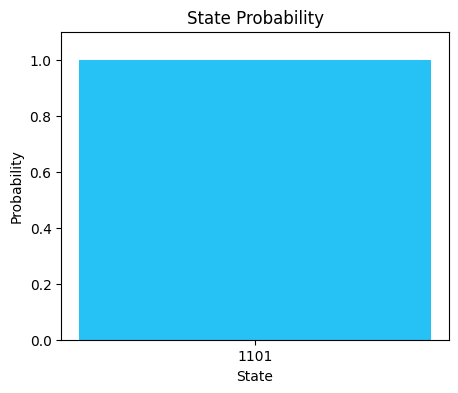

{'1101': np.float64(1.0)}


In [ ]:
clauses = [
    [1,2,3,4],
    [1,2,3,-4],
    [1,2,-3,4],
    [1,2,-3,-4],
    [1,-2,3,4],
    [1,-2,3,-4],
    [1,-2,-3,4],
    [1,-2,-3,-4],
    [-1,2,3,4],
    [-1,2,3,-4],
    [-1,2,-3,4],
    [-1,-2,3,4],
    [-1,-2,3,-4],
    [-1,-2,-3,4],
    [-1,-2,-3,-4]
]
n = 4
n_sol = 1
theta, n_iterations, Probabilities = create_nsat_circuit(n, n_sol, clauses)
print(get_nonzero_states(n, Probabilities, True))

### Four-variable 3-SAT: one solution

Evaluate a 3-SAT instance with four variables and one satisfying assignment. Report the calibrated angle, iteration count, and nonzero state probabilities.

In [ ]:
clauses =  [
    [1, 2, 3],
    [1, 2, -3],
    [1, -2, 3],
    [1, -2, -3],
    [-1, 2, 3],
    [-1, 2, -3],
    [-1, -2, 3],
    [-1, -2, -4]
]
n = 4
n_sol = 1
theta, n_iterations, Probabilities = create_nsat_circuit(n, n_sol, clauses)
print(theta, n_iterations, get_nonzero_states(n, Probabilities))

0.9465349544996785 3 {'0111': np.float64(1.0)}


### Four-variable 3-SAT: two solutions

Evaluate a 3-SAT instance with two satisfying assignments. The reported state-vector probabilities are $0.5$ each for $|0000\rangle$ and $|1111\rangle$.

In [ ]:
clauses =  [
    [-1,  2,  3],
    [-1,  2, -3],
    [ 1, -2,  3],
    [ 1, -2, -3],
    [-2,  3,  4],
    [-2,  3, -4],
    [ 2, -3,  4],
    [ 2, -3, -4],
    [-3,  4,  1],
    [-3,  4, -1],
    [ 3, -4,  1],
    [ 3, -4, -1]
]
n = 4
n_sol = 2
theta, n_iterations, Probabilities = create_nsat_circuit(n, n_sol, clauses)
print(theta, n_iterations, get_nonzero_states(n, Probabilities))

1.0147126064342893 2 {'0000': np.float64(0.5), '1111': np.float64(0.5)}


### Five-variable 3-SAT: two solutions

Apply the same search construction to a five-variable 3-SAT instance with two satisfying assignments. The output assigns probability $0.5$ to each of $|00000\rangle$ and $|11111\rangle$.

In [ ]:
clauses =  [
    [-1,  2,  3],
    [-1,  2, -3],
    [ 1, -2,  3],
    [ 1, -2, -3],
    [-2,  3,  4],
    [-2,  3, -4],
    [ 2, -3,  4],
    [ 2, -3, -4],
    [-3,  4,  5],
    [-3,  4, -5],
    [ 3, -4,  5],
    [ 3, -4, -5],
    [-4,  5,  1],
    [-4,  5, -1],
    [ 4, -5,  1],
    [ 4, -5, -1]
]
n = 5
n_sol = 2
theta, n_iterations, Probabilities = create_nsat_circuit(n, n_sol, clauses)
print(theta, n_iterations, get_nonzero_states(n, Probabilities))

0.9465349544996785 3 {'00000': np.float64(0.5), '11111': np.float64(0.5)}


### Four-variable 4-SAT: two solutions

Evaluate a 4-SAT instance with two satisfying assignments. The final state-vector distribution assigns probability $0.5$ each to $|0010\rangle$ and $|0111\rangle$.

In [ ]:
clauses =  [
    [ 1,  2,  3, -4],
    [ 1,  2, -3,  4],
    [ 1,  2, -3, -4],
    [ 1,  2,  3,  4],
    [ 1, -2,  3, -4],
    [ 1, -2, -3,  4],
    [ 1, -2, -3, -4],
    [-1,  2,  3,  4],
    [-1,  2,  3, -4],
    [-1,  2, -3,  4],
    [-1,  2, -3, -4],
    [-1, -2,  3,  4],
    [-1, -2,  3, -4],
    [-1, -2, -3,  -4]
]
n = 4
n_sol = 2
theta, n_iterations, Probabilities = create_nsat_circuit(n, n_sol, clauses)
print(theta, n_iterations, get_nonzero_states(n, Probabilities))

1.0147126064342893 2 {'0010': np.float64(0.5), '0111': np.float64(0.5)}
